In [7]:
from pathlib import Path
import pandas as pd

def inventory(project):
    proj = Path(project)
    for sh in (1, 2, 3):
        dirs = list((proj / "dlc-models-pytorch").rglob(f"*shuffle{sh}/train"))
        if not dirs:
            print(f"shuffle {sh}: not created"); continue
        d = dirs[0]
        snaps = sorted(p.name for p in d.glob("snapshot-*.pt"))
        ls = d / "learning_stats.csv"
        last = int(pd.read_csv(ls)["step"].max()) if ls.exists() else "?"
        print(f"shuffle {sh}: last epoch {last} | snapshots: {snaps}")

FC = str(next(Path(r".\dlc").glob("flip_clahe-*")))
inventory(FC)

shuffle 1: last epoch 200 | snapshots: ['snapshot-100.pt', 'snapshot-125.pt', 'snapshot-150.pt', 'snapshot-175.pt', 'snapshot-200.pt', 'snapshot-best-020.pt']
shuffle 2: last epoch 130 | snapshots: ['snapshot-025.pt', 'snapshot-050.pt', 'snapshot-075.pt', 'snapshot-100.pt', 'snapshot-125.pt', 'snapshot-best-030.pt']
shuffle 3: last epoch ? | snapshots: []


In [8]:
from src import viz

def find(name):
    return str(next(Path(r".\dlc").glob(f"{name}-*")))

SCEN = {1: "hard", 2: "easy", 3: "mixed"}

def compare(projects):
    rows = []
    for name, path in projects.items():
        for sh, scen in SCEN.items():
            try:
                _, evals = viz.load_training_stats(path, sh)
                b = evals.loc[evals["metrics/test.rmse"].idxmin()]
                rows.append([name, scen, int(b["step"]),
                             round(b["metrics/test.rmse"], 1),
                             round(b["metrics/test.rmse_pcutoff"], 1),
                             round(b["metrics/test.mAP"], 1)])
            except Exception:
                rows.append([name, scen, "—", "not trained", "—", "—"])
    return pd.DataFrame(rows, columns=["experiment","scenario","best_epoch","rmse_px","rmse_pcutoff","mAP"])

projects = {"baseline": find("baseline"), "flip": find("flip"), "flip_clahe": find("flip_clahe")}
print(compare(projects).to_string(index=False))

experiment scenario best_epoch     rmse_px rmse_pcutoff   mAP
  baseline     hard         10        47.0          4.6   8.5
  baseline     easy         10         4.6          4.5  99.7
  baseline    mixed        190         3.3          3.3  96.6
      flip     hard         10        15.9          8.1  70.7
      flip     easy         50         4.6          4.5  99.7
      flip    mixed        110         3.4          3.3  96.4
flip_clahe     hard         20        13.5          8.5  69.4
flip_clahe     easy         80         4.2          4.1  99.5
flip_clahe    mixed          — not trained            —     —


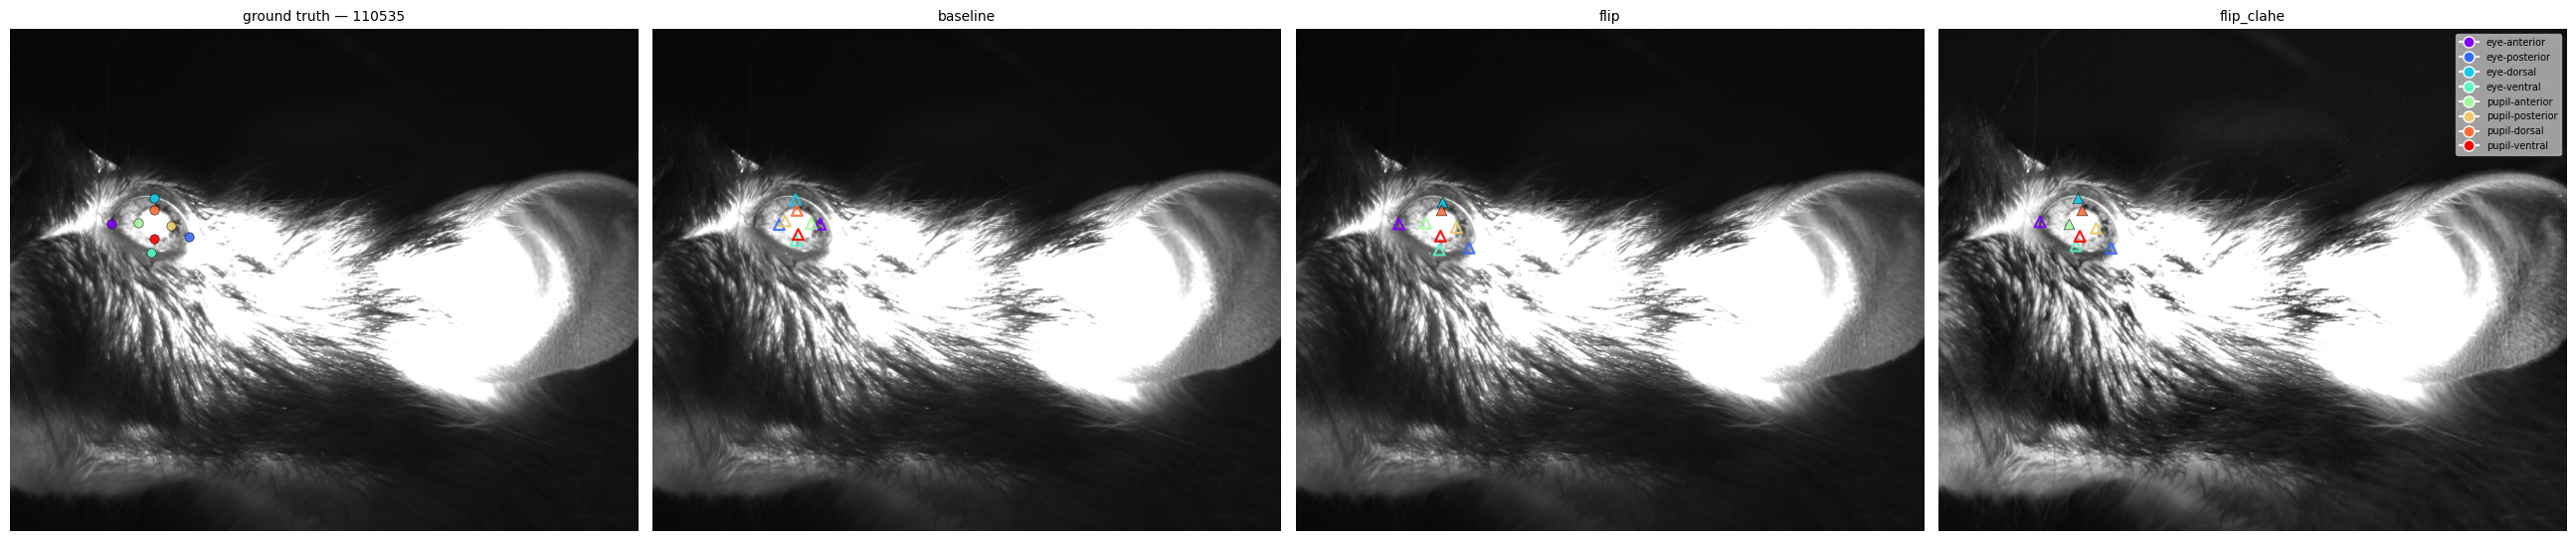

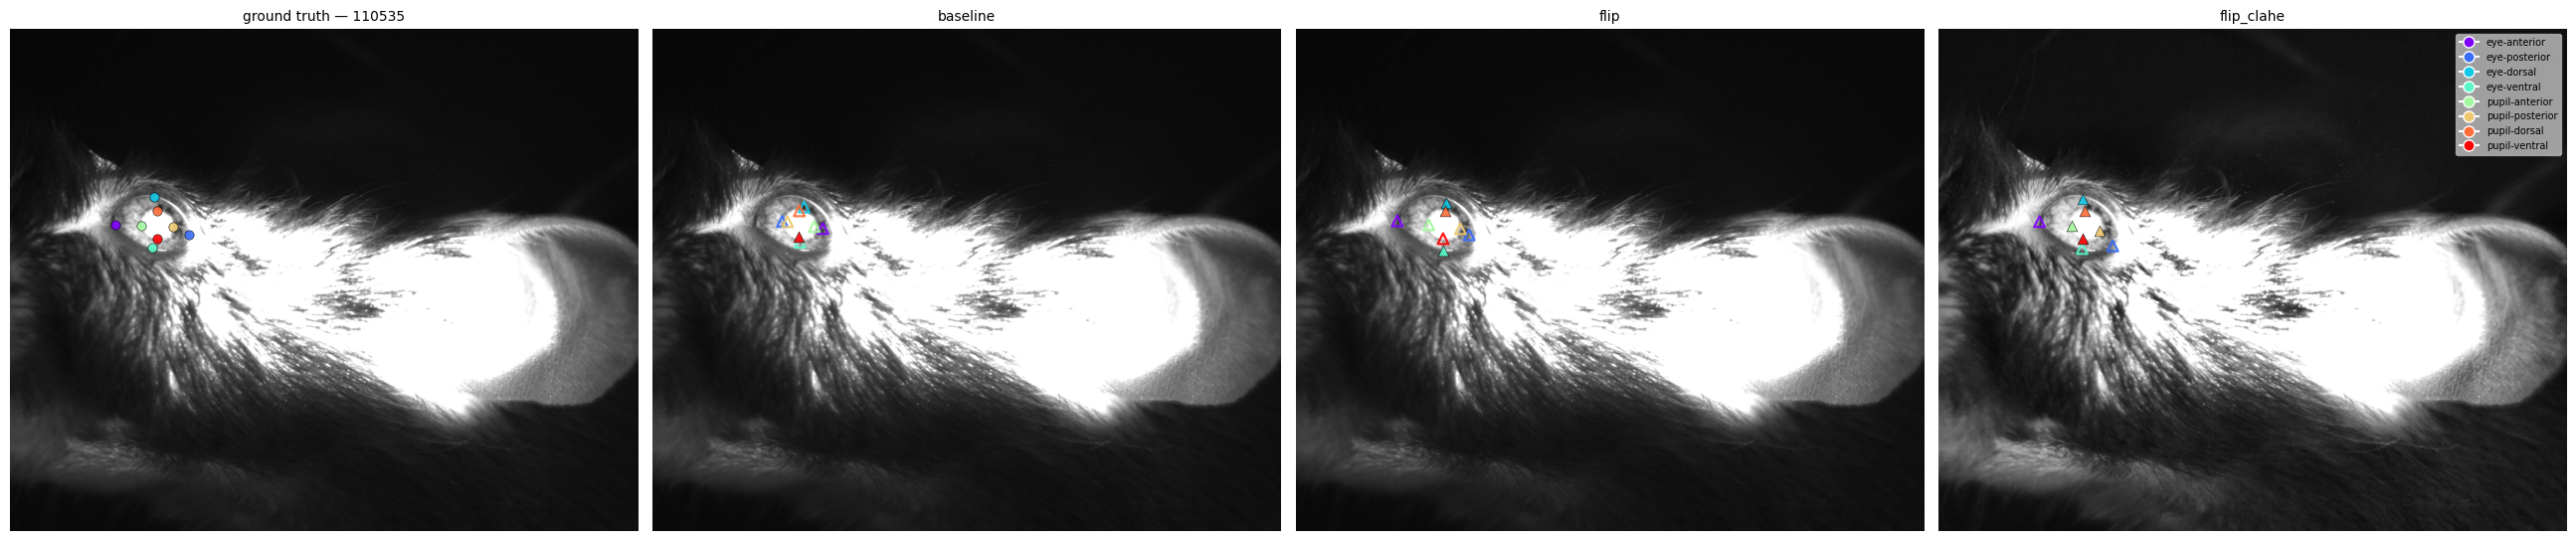

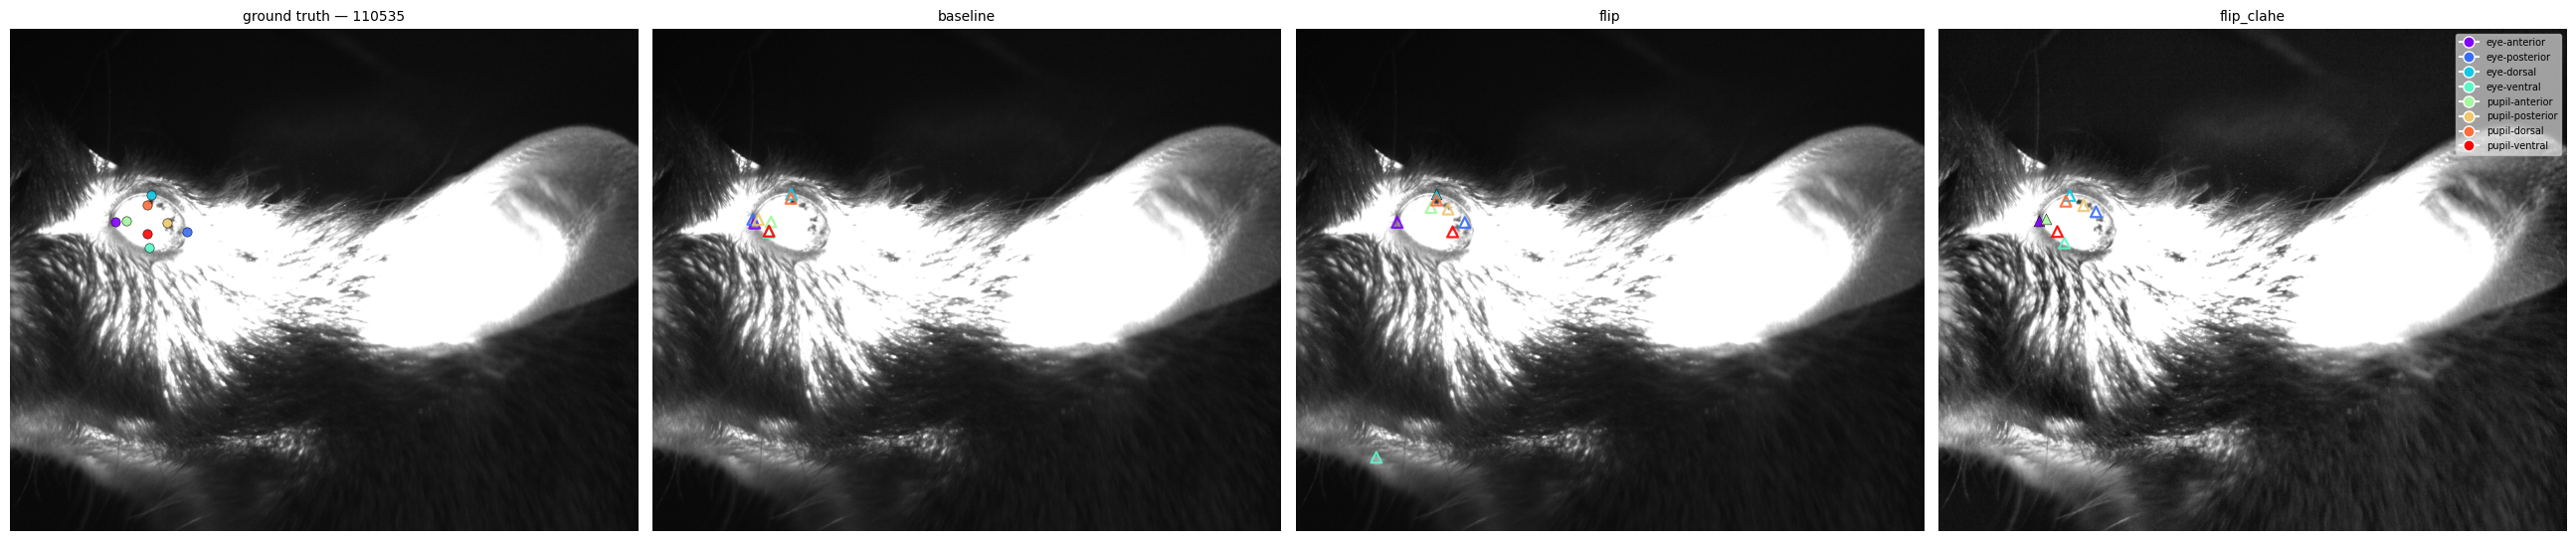

In [20]:
models = {"baseline": find("baseline"), "flip": find("flip"), "flip_clahe": find("flip_clahe")}
viz.compare_models(models, "110535", shuffle=1)

viz.compare_models(models, "110535", "img040509.png", shuffle=1)

viz.compare_models(models, "110535", "img195288.png", shuffle=1)

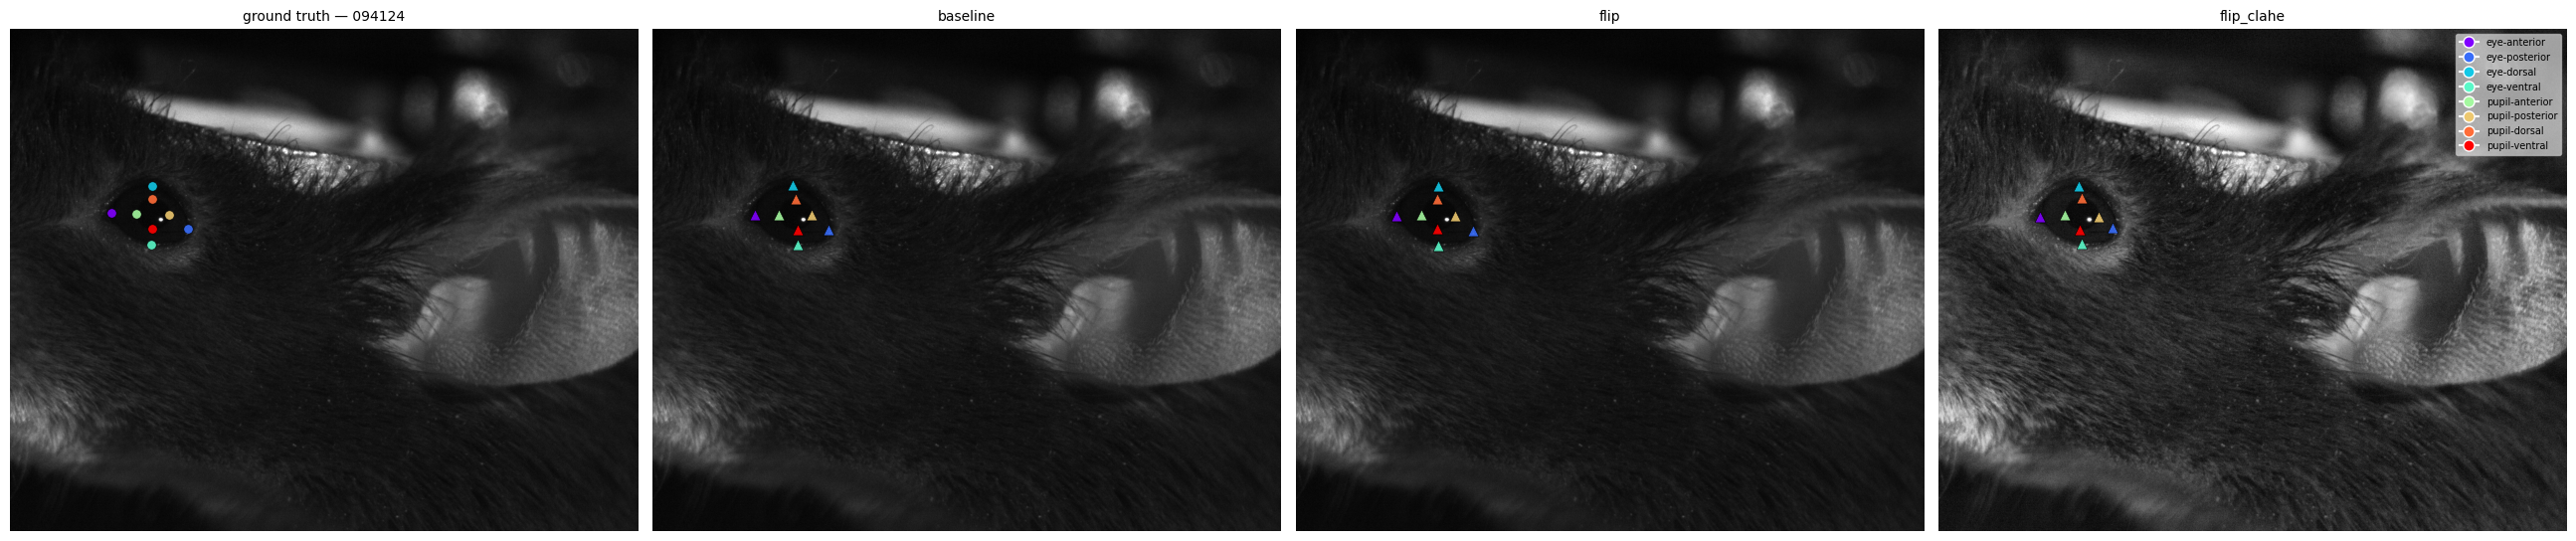

In [14]:
models2 = {"baseline": find("baseline"), "flip": find("flip"), "flip_clahe": find("flip_clahe")}
viz.compare_models(models2, "094124", shuffle=2)

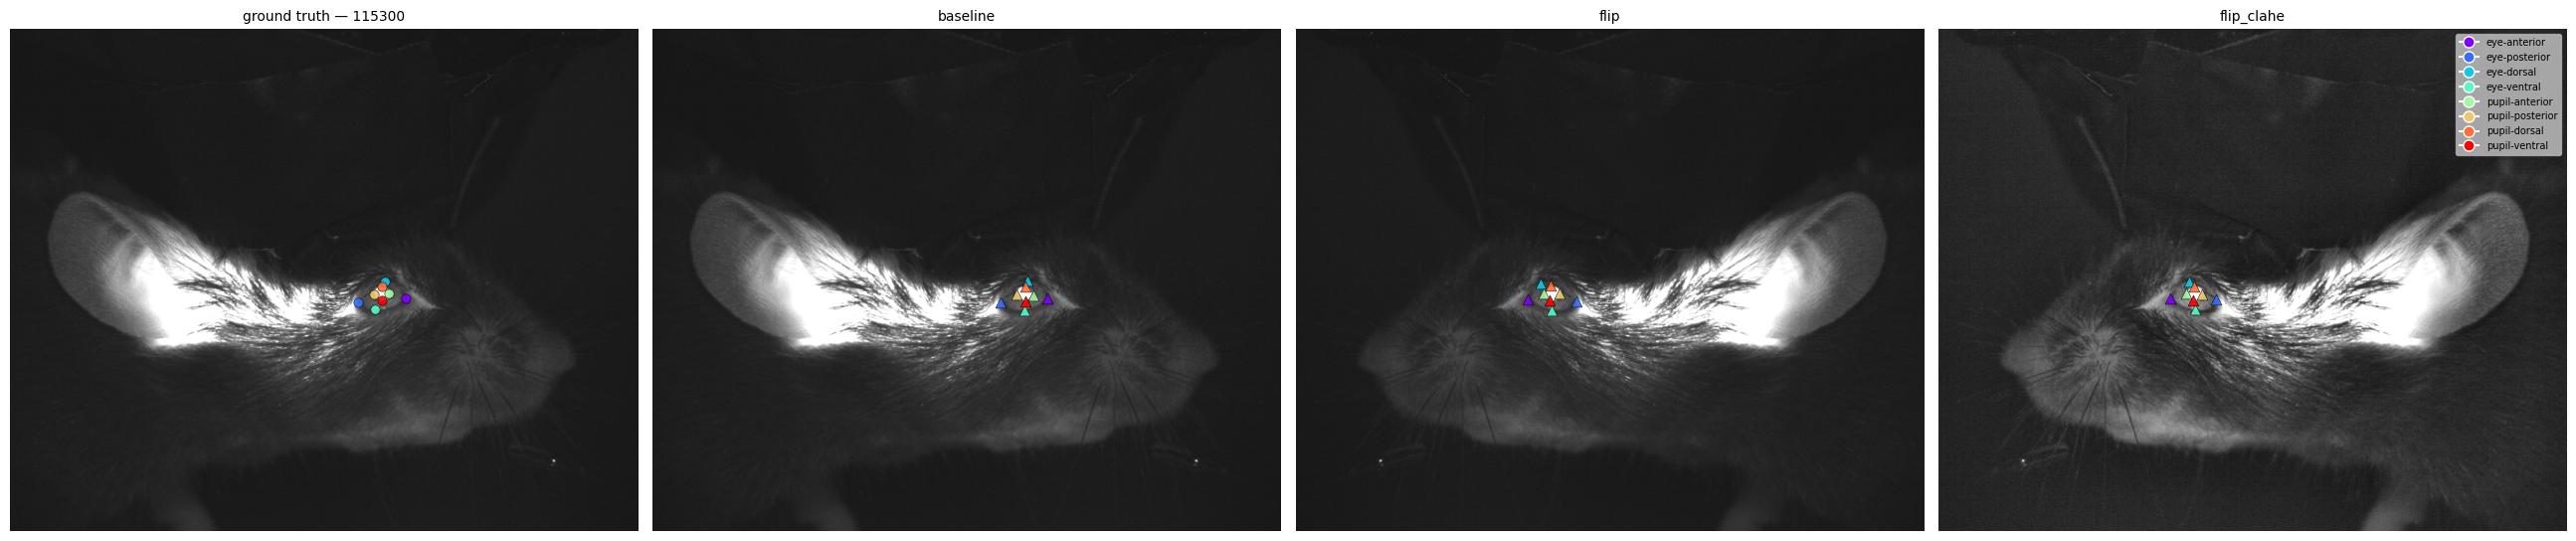

In [17]:
viz.compare_models(models2, "115300", shuffle=2)